![](https://img.shields.io/badge/PO.DAAC-Contribution-%20?color=grey&labelColor=blue)
or 
![](https://img.shields.io/badge/Community-Contribution-%20?color=grey&labelColor=yellow)

> From the PO.DAAC Cookbook, to access the GitHub version of the notebook, follow [this link]((https://github.com/podaac/tutorials/blob/master/notebooks/datasets/SWOT_Pixel_Assignment_example.ipynb)).

# SWOT Pixel Assignement Example
#### *Author: Brent Williams, Jet Propulstion Lab*
_Last updated: 23 October 2026_

## Summary

This tutorial overviews some concepts that are useful to consider when users want to create their own custom pixel assignment algorithm to assign PIXC pixels to features on the ground (e.g., a lake, or river reach etc).  Depending on the application, handling the issues outlined here may seem subtle, but can be significant.  We present a naive approch that simply uses the geolocations of each pixel to assign to a feature.  However, because the geolocation noise of each pixel is generally much larger than the pixel size itself (and possibly larger than the size of the feature), this can result in pixels being missed as well as pixels that are not in the desired feature being incorectly assigned (which often have anomolous heights).  Several other quantities such as slant-plane connectivity, height similarity, as well as classification and quality flags can be useful to enhance and regularize the pixel assignement process.

## Requirements

### 1. Compute Environment
This tutorial can be run in the following environments:
- Local compute environment e.g. laptop, server: this tutorial can be run on your local machine

### 2. Earthdata Login
An Earthdata Login account is required to access data, as well as discover restricted data, from the NASA Earthdata system. Thus, to access NASA data, you need Earthdata Login. Please visit https://urs.earthdata.nasa.gov to register and manage your Earthdata Login account. This account is free to create and only takes a moment to set up.

### 3. Libraries Needed

Note: To import SWOTWater, use the following pip install for the RiverObs GitHub repository:

> pip install git+https://github.com/SWOTAlgorithms/RiverObs.git --no-cache-dir


## Learning Objectives

This tuorial outlines how to:
- Assign pixels to ground features using
    - Naive assignement
    - Slant-plane connectivity
    - Height similarity constraints
- Convert PIXC height to WSE (as reported in the river/lake/raster products)
- Aggregate wse with the standard tools to produce the minimum variance linear estimate that properly handles correlation between pixels

## Import Packages

In [1]:
import xarray as xr
import matplotlib.pyplot as plt
import numpy as np
import scipy.ndimage

import pandas as pd
import geopandas as gpd
from shapely.geometry import Polygon #Point, MultiPolygon, Polygon
import SWOTWater.aggregate
import earthaccess

## Define a Polygon Feature
Note that this example is of a glacial lake polygon (Snow Lake) that is not in the Lake Database, so users would need to do something special to assign pixels to this polygon.  Details for this specific polygon (as well as data files) are referenced here: https://doi.org/10.5066/P1UR7DHM.

Here we manually define the polygon to be explicit.  We also produce a dilated version of the polygon for later use in the pixel-assignment algorithms.

<Axes: >

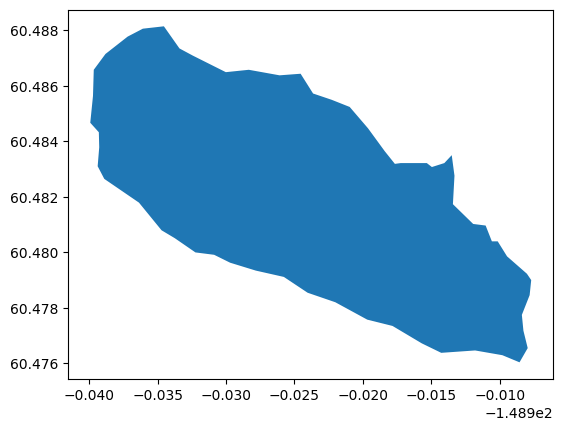

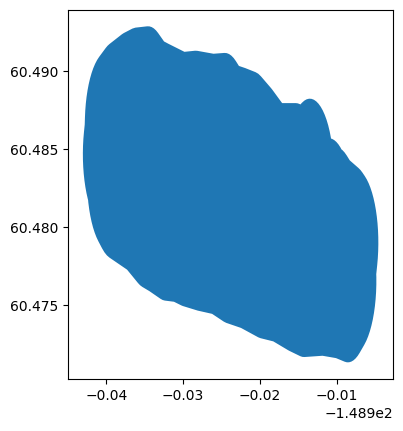

In [2]:
# define a polygon manually
coords = [(-148.93992554696413, 60.48466499465735, 0.0),
 (-148.93972620529777, 60.48563322590587, 0.0),
 (-148.93966925008954, 60.48657298007106, 0.0),
 (-148.93881492821586, 60.48714252798686, 0.0),
 (-148.93719171676005, 60.48776903006922, 0.0),
 (-148.93608109905344, 60.48805380402706, 0.0),
 (-148.93454331988917, 60.4881392363186, 0.0),
 (-148.9334042240576, 60.487341869653164, 0.0),
 (-148.9324359928091, 60.4870855727786, 0.0),
 (-148.93001541468786, 60.48648754777952, 0.0),
 (-148.92833524906547, 60.48657298007106, 0.0),
 (-148.9260855355273, 60.4863736384047, 0.0),
 (-148.924547756363, 60.486430593612965, 0.0),
 (-148.92363648032276, 60.48571865819736, 0.0),
 (-148.92226956574154, 60.48549083944772, 0.0),
 (-148.9209596053269, 60.48523454257315, 0.0),
 (-148.919621167829, 60.48446565299099, 0.0),
 (-148.91839664074757, 60.48363980924228, 0.0),
 (-148.91765622824872, 60.48318417070129, 0.0),
 (-148.9172290678327, 60.483212647784626, 0.0),
 (-148.9158906303348, 60.483212647784626, 0.0),
 (-148.915321082419, 60.483212647784626, 0.0),
 (-148.91495087616957, 60.483070261326475, 0.0),
 (-148.9140396001293, 60.483212647784626, 0.0),
 (-148.91349852929682, 60.48349742174247, 0.0),
 (-148.91329918763049, 60.4827570102853, 0.0),
 (-148.9134130970053, 60.48173182382857, 0.0),
 (-148.91193227304927, 60.48101988945467, 0.0),
 (-148.91102099700902, 60.480962934246406, 0.0),
 (-148.91056535846806, 60.48039338633066, 0.0),
 (-148.91013819701038, 60.48039338633066, 0.0),
 (-148.90945473971976, 60.47985231653979, 0.0),
 (-148.90800239284704, 60.47922581341578, 0.0),
 (-148.90768914180586, 60.478997994666145, 0.0),
 (-148.90780305118068, 60.478456923833676, 0.0),
 (-148.90837259909645, 60.47774498945978, 0.0),
 (-148.90825868972163, 60.47717544154398, 0.0),
 (-148.90794543868046, 60.47654893946162, 0.0),
 (-148.90854346367954, 60.47603634571243, 0.0),
 (-148.9097964688859, 60.476292642587, 0.0),
 (-148.9117898855495, 60.47646350717008, 0.0),
 (-148.91426741887898, 60.47637807487854, 0.0),
 (-148.91569128866843, 60.47671980300299, 0.0),
 (-148.91782709283177, 60.47734630612706, 0.0),
 (-148.91967812303724, 60.477574124876696, 0.0),
 (-148.92201326886695, 60.47820062800071, 0.0),
 (-148.92403516365547, 60.47854235612516, 0.0),
 (-148.9257722844861, 60.47911190404096, 0.0),
 (-148.92782265635793, 60.4793397227906, 0.0),
 (-148.92970216364668, 60.4796244967485, 0.0),
 (-148.93086973656153, 60.4799092707064, 0.0),
 (-148.93223665114274, 60.47999470299794, 0.0),
 (-148.93374595322373, 60.48050729570548, 0.0),
 (-148.93471418447223, 60.48079206966338, 0.0),
 (-148.93636587301134, 60.48178877903683, 0.0),
 (-148.9389003605074, 60.482643099868824, 0.0),
 (-148.93938447613164, 60.48309873840975, 0.0),
 (-148.93927056675682, 60.48378219570037, 0.0),
 (-148.93929904384012, 60.4843232665329, 0.0),
 (-148.93992554696413, 60.48466499465735, 0.0)]

poly = Polygon(coords)
gdf = gpd.GeoDataFrame(index=[0], crs='EPSG:5498', geometry=[poly])

# Also get a dilated version of the polygon to be used later to limit pixel assignment extent
# This is done by projecting to equiarea crs and then dliating by certain number of meters and then putting back in lat/lon

buffer_dist_in_meters = 300
crs = gdf.crs
gdf_d = gpd.GeoDataFrame(
    geometry=gdf.to_crs(epsg=6933).buffer(
        buffer_dist_in_meters).to_crs(crs))

# also define a bounding box

bbox_df = gdf.bounds
bbox = [
    float(bbox_df['minx'][0]),
    float(bbox_df['maxx'][0]),
    float(bbox_df['miny'][0]),
    float(bbox_df['maxy'][0])
    ]

# plot both polygons

gdf.plot()
gdf_d.plot()

## Download the desired PIXC tile

In [3]:
# first authenticate

auth = earthaccess.login()

# now download the pixc file
pixc_results = earthaccess.search_data(short_name = 'SWOT_L2_HR_PIXC_D', 
                                        granule_name = '*038_470_047L_*')

files = earthaccess.download([pixc_results[0]], "./data_downloads")

pixc_file = str(files[0])
print(pixc_file)
#pixc_file = 'data_downloads/SWOT_L2_HR_PIXC_038_470_047L_20250916T233803_20250916T233814_PID0_01.nc'


Enter your Earthdata Login username:  brent.a.williams@jpl.nasa.gov
Enter your Earthdata password:  ········


QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

data_downloads/SWOT_L2_HR_PIXC_038_470_047L_20250916T233803_20250916T233814_PID0_01.nc


## Read the PIXC file
Load the desired PIXC data into slant-plane arrays cropped around the feature for convenience.

In [4]:
# Define Functions for Reading PIXC Data into slant-plane images then read it

def toslant(pixc, key='height', fill=np.nan):
    az = pixc.azimuth_index.astype(int)
    rng = pixc.range_index.astype(int)
    out = np.zeros((pixc.interferogram_size_azimuth + 1, pixc.interferogram_size_range + 1)) + fill
    var = pixc[key]
    if key =='interferogram':
        out = out.astype(complex)
        out[az, rng] = var[:,0] + 1j * var[:,1]
    else:
        out[az, rng] = var
    return out


def read_segment_and_crop_pixc(pixc_file, bbox,
        bbox_buff = 0.001, slant_buff=10, keys=None):
    if keys==None:
        keys = [
            'classification',
            'classification_qual',
            'latitude',
            'longitude',
            'height',
            'prior_water_prob',
            'sig0',
            'dheight_dphase',
            'dlatitude_dphase',
            'dlongitude_dphase',
            'geoid',
            'solid_earth_tide',
            'load_tide_fes',
            'pole_tide',
            'phase_noise_std',
            'power_plus_y',
            'power_minus_y',
            'interferogram',
            'eff_num_rare_looks',
            'eff_num_medium_looks'
            ]
    pixc = {}
    with xr.load_dataset(pixc_file, group='pixel_cloud') as ds:
        # read the desired variables
        #print([k for k in ds.variables.keys()])
        for key in keys:
            pixc[key] = toslant(ds, key)
        looks_to_efflooks = float(ds.looks_to_efflooks)
    #
    # convert from height (above ellipsoid) to wse
    # (e.g., relative to geoid and with earth tides applied)
    #
    pixc['wse'] = pixc['height'] - (
        pixc['geoid'] +
        pixc['solid_earth_tide'] +
        pixc['load_tide_fes'] +
        pixc['pole_tide'])
    
    ####
    # do image segmentation before cropping
    #     Note that we use information on image segmentation
    #     later in the pixel-assignment algorithms but it
    #     needs to be done here before we crop the image to
    #     use the context of the larger image
    ####
    seg_mask = np.zeros(np.shape(pixc['classification']))
    seg_mask[pixc['classification']>2] = 1
    # TODO: don't use specular ringing or lowcoh unless it is in the prior too
    #
    lab, nlabs = scipy.ndimage.label(seg_mask)
    pixc['segmentation_mask'] = seg_mask
    pixc['segmentation_label'] = lab

    ####
    # crop to bbox
    ####
    # find the pixels within the bbox
    msk = np.logical_and.reduce((
        pixc['longitude']>bbox[0] - bbox_buff,
        pixc['longitude']<bbox[1] + bbox_buff,
        pixc['latitude']>bbox[2] - bbox_buff,
        pixc['latitude']<bbox[3] + bbox_buff,
        ))
    inds = np.where(msk)
    # get the slant-plane square bounds
    az0 = int(np.min(inds[0])) - slant_buff
    az1 = int(np.max(inds[0])) + slant_buff
    r0 = int(np.min(inds[1])) - slant_buff
    r1 = int(np.max(inds[1])) + slant_buff
    # crop the data variables
    for key in pixc.keys():
        pixc[key] = pixc[key][az0:az1, r0:r1]
    pixc['looks_to_efflooks'] = looks_to_efflooks
    return pixc
                        

# read it
pixc = read_segment_and_crop_pixc(pixc_file, bbox)

# Do Naive Pixel Assignement
This merely finds the pixels where the noisy geolocations are within the polygon

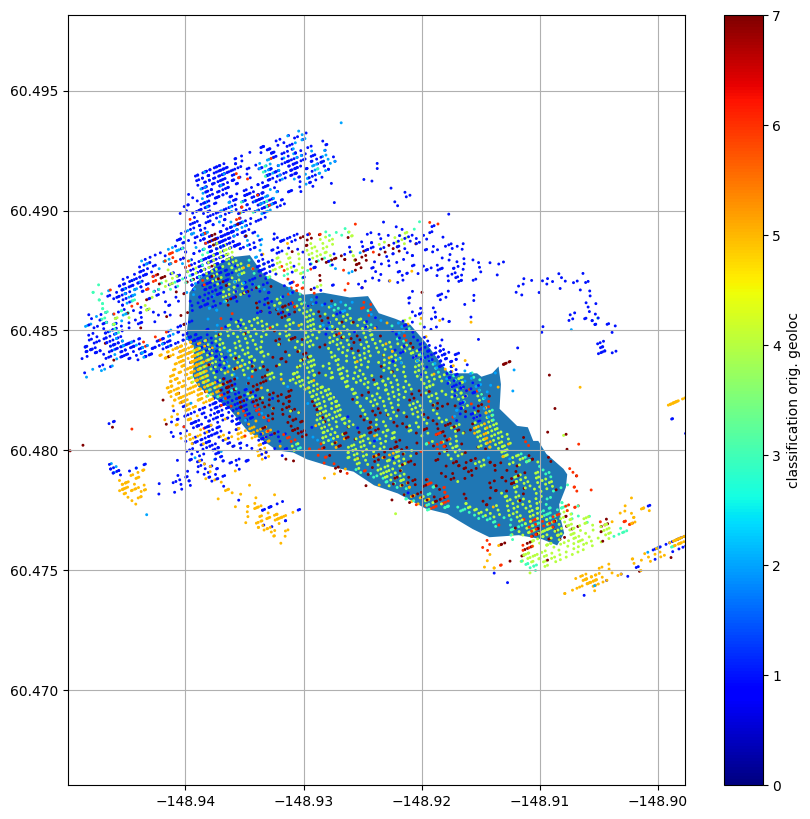

In [5]:
# first define a function for intersecting pixels with polygon

def find_within(gdf, lat, lon, msk):
    df = pd.DataFrame({
        'latitude':lat[msk],
        'longitude':lon[msk],
        })
    geometry = gpd.points_from_xy(df['longitude'], df['latitude'])
    point_gdf = gpd.GeoDataFrame(df, geometry=geometry, crs="EPSG:5498")
    point_intx_gdf = gpd.sjoin(point_gdf, gdf, how='inner', predicate='intersects')
    # now put the pixels that are in polygon back into the slant-plane
    in_mask_1D = np.zeros_like(lat[msk])
    in_mask_1D[point_intx_gdf.index] = 1
    in_mask_2D = np.zeros_like(lat)
    in_mask_2D[msk] = in_mask_1D
    return point_gdf, point_intx_gdf, in_mask_2D

# also 


# now find the mask of pixels within the polygon
msk = np.isfinite(pixc['latitude'])
point_gdf, point_intx_gdf, in_mask_2D = find_within(
    gdf, pixc['latitude'], pixc['longitude'], msk)


# Define a Function to Produce Pixel-assignment Masks Based on Various Criteria
#Get masks of pixels where we trust the pixels are associated with the desired feature based on:
# 1) detected as open water
# 2) refined geolocations being in the polygon
# 3) is the same connected water feature in slant-plane
# 4) heights are not outliers
def compute_masks(in_mask_2D, pixc):
    # get a finial mask of pixels the we trust the heights based on
    # 1) detected as open water
    det = np.logical_and(pixc['classification']>2, pixc['classification']!=5)
    # 2) refined geolocations being in the polygon
    water_in = np.logical_and(det, in_mask_2D==1)
    # 3) is the same connected water feature in slant-plane
    res = scipy.stats.mode(pixc['segmentation_label'][water_in])
    dom_lab = int(res.mode)
    water_seg_in = np.logical_and(water_in, pixc['segmentation_label']==dom_lab)
    # 4) heights are not outliers
    med = np.nanpercentile(pixc['height'][water_seg_in==1],50)
    p25 = np.nanpercentile(pixc['height'][water_seg_in==1],25)
    p75 = np.nanpercentile(pixc['height'][water_seg_in==1],75)
    iqr = p75-p25
    outliers = np.abs(pixc['height'] - med) > 3 * iqr
    good_height_mask = np.logical_and(water_seg_in, np.logical_not(outliers))
    # 5 ) TODO: should also chack qual flags and maybe also the height nose std?
    
    masks = {}
    masks['water'] = det
    masks['water_in'] = water_in
    masks['water_seg_in'] = water_seg_in
    masks['height_outliers'] = outliers
    masks['water_seg_in_no_outliers'] = good_height_mask
    return masks

# now get the pixel assignement mask(s) associated with this Naive algorithm
masks = compute_masks(in_mask_2D, pixc)

# now plot the naive pixel assignement case in ground-plane

# first plot the noisy geolocation with the polygon
buff = 0.01
ax = gdf.plot(figsize=(10,10))
im = ax.scatter(
    pixc['longitude'][msk],
    pixc['latitude'][msk],
    c=pixc['classification'][msk],
    cmap='jet', clim=(0,7), s=1.2)
ax.set_xlim(float(bbox_df['minx'][0])-buff, float(bbox_df['maxx'][0])+buff)
ax.set_ylim(float(bbox_df['miny'][0])-buff, float(bbox_df['maxy'][0])+buff)
plt.colorbar(im,label='classification orig. geoloc')
plt.grid()

## Define a Function for Plotting Slant-plane Multipanel Images
Plot 5-pannels of various pixel assignment related variables with the pixels within the polygon highlighted.

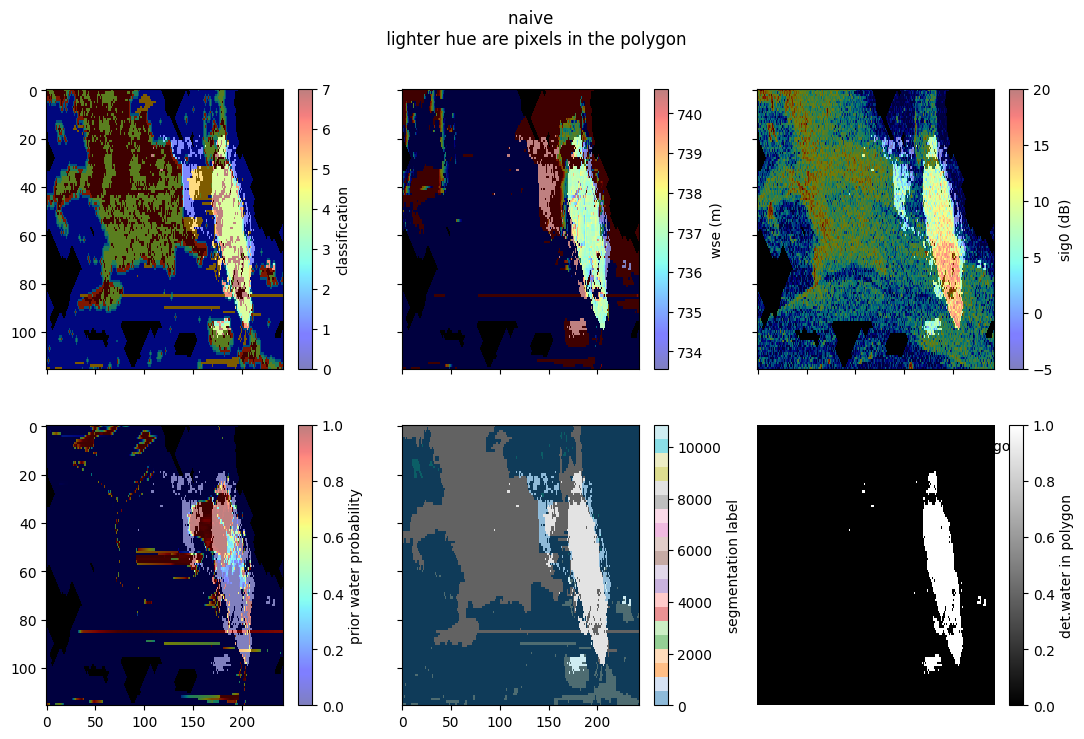

In [6]:
def plot_multipanel(in_mask_2D, pixc,
        final_mask=None, final_label=None, title=None):
    # get the height colorbar limits
    det = np.logical_and(pixc['classification']>2, pixc['classification']!=5)
    water_in = np.logical_and(det, in_mask_2D==1)
    res = scipy.stats.mode(pixc['segmentation_label'][water_in])
    dom_lab = int(res.mode)
    water_seg_in = np.logical_and(water_in, pixc['segmentation_label']==dom_lab)
    #med = np.nanpercentile(pixc['height'][water_seg_in==1],50)
    #p25 = np.nanpercentile(pixc['height'][water_seg_in==1],25)
    #p75 = np.nanpercentile(pixc['height'][water_seg_in==1],75)
    med = np.nanpercentile(pixc['wse'][water_seg_in==1],50)
    p25 = np.nanpercentile(pixc['wse'][water_seg_in==1],25)
    p75 = np.nanpercentile(pixc['wse'][water_seg_in==1],75)
    iqr = p75-p25
    #
    climh = (
        med - 5*iqr,
        med + 5*iqr
        )
    # plot things
    fig, axs = plt.subplots(2,3, sharey=True,sharex=True,figsize=(13,8))
    axs[0,0].imshow(in_mask_2D,
        interpolation='none', aspect='auto', cmap='gray')
    im=axs[0,0].imshow(pixc['classification'],
        interpolation='none', aspect='auto',
        cmap='jet', clim=(0,7), alpha=0.5)
    fig.colorbar(im,label='classification')
    #
    axs[0,1].imshow(in_mask_2D,
        interpolation='none', aspect='auto', cmap='gray')
    im=axs[0,1].imshow(pixc['wse'],#pixc['height'],
        interpolation='none', aspect='auto',
        cmap='jet', clim=climh, alpha=0.5)
    fig.colorbar(im,label='wse (m)')
    #
    axs[0,2].imshow(in_mask_2D,
        interpolation='none', aspect='auto', cmap='gray')
    sig0 = pixc['sig0']
    sig0[sig0<0] = 1e-15
    im = axs[0,2].imshow(10*np.log10(sig0),
        interpolation='none', aspect='auto',
        cmap='jet', clim=(-5,20), alpha=0.5)
    fig.colorbar(im,label='sig0 (dB)')
    #
    axs[1,0].imshow(in_mask_2D,
        interpolation='none', aspect='auto', cmap='gray')
    im = axs[1,0].imshow(pixc['prior_water_prob'],
        interpolation='none', aspect='auto',
        cmap='jet', clim=(0,1), alpha=0.5)
    fig.colorbar(im,label='prior water probability')
    #
    axs[1,1].imshow(in_mask_2D,
        interpolation='none', aspect='auto', cmap='gray')
    im = axs[1,1].imshow(pixc['segmentation_label'],
        interpolation='none', aspect='auto',
        cmap='tab20', alpha=0.5)
    fig.colorbar(im,label='segmentation label')
    #
    #im = axs[1,2].imshow(good_height_mask.astype(int),
    #    interpolation='none', aspect='auto', cmap='gray')
    #fig.colorbar(im,label=good_height_label)
    if final_mask is not None:
        im = axs[1,2].imshow(final_mask.astype(int),
            interpolation='none', aspect='auto', cmap='gray')
    if final_label is not None:
        fig.colorbar(im,label=final_label)
    axs[1,2].axis('off')
    axs[1,2].text(10, 10, 'lighter hue are pixels in the polygon')
    if title is not None:
        plt.suptitle(title+' \n lighter hue are pixels in the polygon')

# now plot the slant-plane images
plot_multipanel(in_mask_2D, pixc,
    final_mask=masks['water_in'],
    final_label='det.water in polygon',
    title='naive')

## Naive Pixel-assignement Discussion
Note that the geolocation of each pixel is generally much noisier than the pixel size (and mostly in the cross-track direction).  This causes many pixels that should be in the feature to not be selected/assigned, as well as other pixels that are not part of the feature to be eroneously selected/assigned. In these images the lighter hue correspond to the pixels within the polygon.  The botom right image shows the slant-plane mask of assigned pixels that are within the polygon and detected as water (i.e., this is the naive pixel assignement of water pixels).  Note that inthe bottom right image there are still some spurious pixels that are not part of the same feature (as they are disjoint in slant-plane), and many of these have significantly different heights.  Furthermore, there are some pixels within the main selected feature that have reduced height quality (depicted as variations in the height image that is probably due to layover as those areas are also typically near low-coherence classes).  We can clean up these problematic pixels by doing something a bit more sophisticated as we will see below. 

### Handle slant-plane connectivity and height outliers

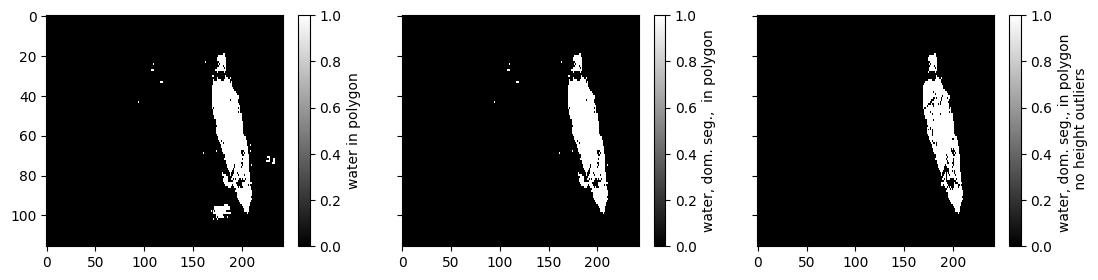

In [7]:
# Define a Plotter Function for the Various Masks related to slant-plane connectivity and height outliers
def plot_masks(masks, title=None):
    fig, axs = plt.subplots(1,3, sharey=True,sharex=True,figsize=(13,3))
    #
    im = axs[0].imshow(masks['water_in'].astype(int),
        interpolation='none', aspect='auto', cmap='gray')
    fig.colorbar(im, label='water in polygon')
    #
    im = axs[1].imshow(masks['water_seg_in'].astype(int),
        interpolation='none', aspect='auto', cmap='gray')
    fig.colorbar(im, label='water, dom. seg.,  in polygon')
    #
    im = axs[2].imshow(masks['water_seg_in_no_outliers'].astype(int),
        interpolation='none', aspect='auto', cmap='gray')
    fig.colorbar(im, label='water, dom. seg., in polygon \n no height outliers')

    if title is not None:
        fig.suptitle(title)

# plot these masks
plot_masks(masks)

Note that if we use image segmentation in the slant-plane to filter out pixels that are not in the "dominant" label we can filter out some of the problem pixels (middle figure).  Furthermore, if we do height outlier rejection, we can get even better (right panel).  However, we can still do better by improving (reducing) the geolocation noise of each pixel before assigning to the water features as we will show below.

# Do More Sophisticated Pixel Assignment
This is done by first assigning the noisy geolocated pixels to the polygon, then fintering out pixels that are not expected to be the same feature using connectivity in the slant-plane.  After this, we estimate the median height and then refine the geolocations (i.e., applying an approximation to the height-constrained geolocation). This is done by forcing the pixels in the whole area (not just the feature) to be at that height and moving along the gelocation sensitvity vector for each pixel (e.g., dlat/dheight and dlon/dheight).  This produces an approximation of the "improved geolocation" that the PIXCVEC algorithm performs.

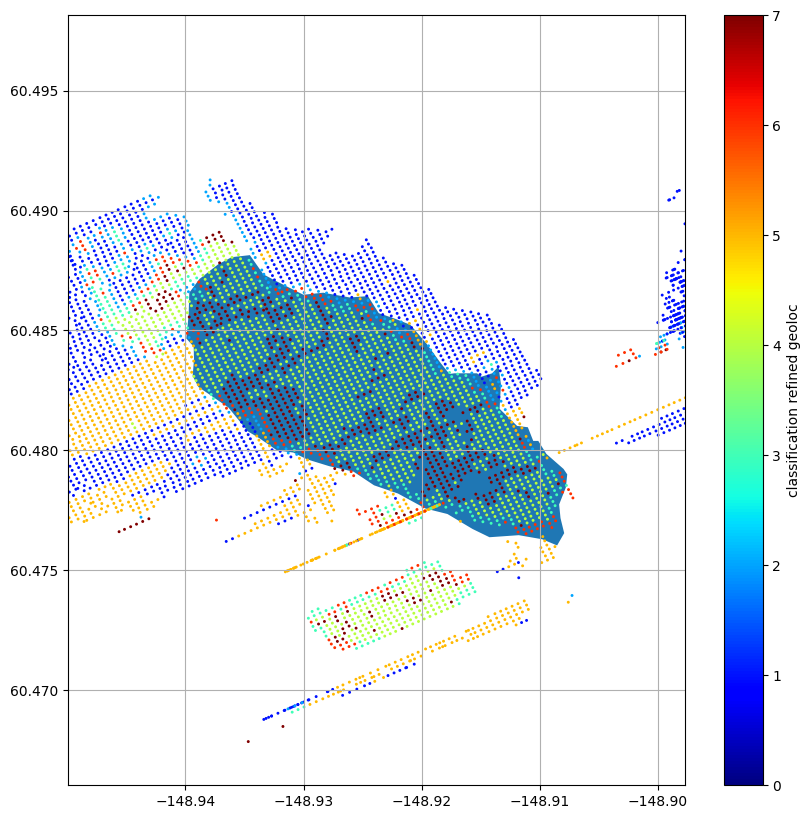

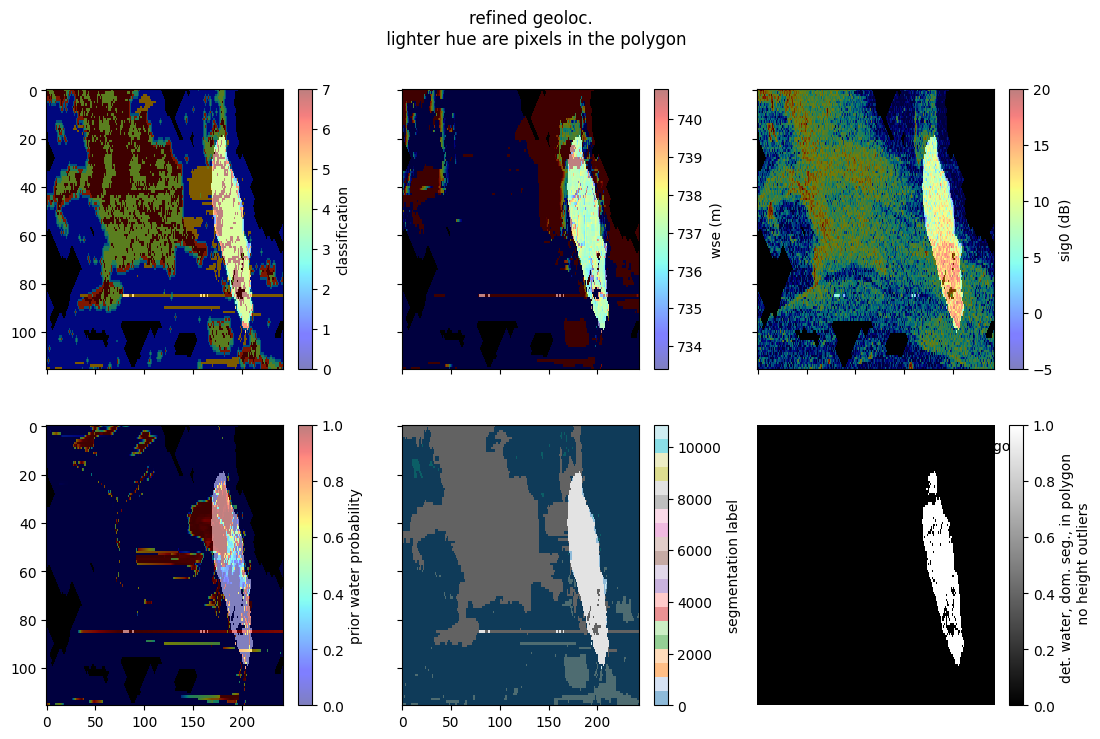

In [8]:
# find dominant segmentation label
trusted_water_for_height = pixc['classification']==4
water_in = np.logical_and(trusted_water_for_height, in_mask_2D==1)
res = scipy.stats.mode(pixc['segmentation_label'][water_in])
dom_lab = int(res.mode)
water_seg_in = np.logical_and(water_in, pixc['segmentation_label']==dom_lab)
# get aggregate statistics for reineing geolocation
# and outlier detection
med = np.nanpercentile(pixc['height'][water_seg_in==1],50)
p25 = np.nanpercentile(pixc['height'][water_seg_in==1],25)
p75 = np.nanpercentile(pixc['height'][water_seg_in==1],75)
iqr = p75-p25

# get refined geolocations assuming height of median height
# over trusted pixels
dh_ = pixc['height'] - med
# clip maximum change in height
# since the derivatives approximation breaks down
# far from the pixc height
max_dh = 50
dh = dh_.copy()
dh[dh_>max_dh] = max_dh
dh[dh_<-max_dh] = -max_dh
#
dlat_dh = pixc['dlatitude_dphase'] / pixc['dheight_dphase']
dlon_dh = pixc['dlongitude_dphase'] / pixc['dheight_dphase']
lat_new = pixc['latitude'] - dlat_dh * dh
lon_new = pixc['longitude'] - dlon_dh * dh

#
# now find within dilated polygon using refined locations
#
msk0 = np.isfinite(lat_new)
# also get the case without dilating polygon
point_gdf1, point_intx_gdf1, in_mask_2D1 = find_within(
    gdf, lat_new, lon_new, msk0)
# also get the assignement masks
masks1 = compute_masks(in_mask_2D1, pixc)



# Now Plot the More Sophisticated Case 

#ax = gdf_d.plot( alpha=0.5)
ax = gdf.plot(figsize=(10,10))
im = ax.scatter(
    lon_new[msk0],
    lat_new[msk0],
    c=pixc['classification'][msk0],
    cmap='jet', clim=(0,7), s=1.2)
ax.set_xlim(float(bbox_df['minx'][0])-buff, float(bbox_df['maxx'][0])+buff)
ax.set_ylim(float(bbox_df['miny'][0])-buff, float(bbox_df['maxy'][0])+buff)
plt.colorbar(im,label='classification refined geoloc')
ax.grid()

plot_multipanel(in_mask_2D1, pixc,
    final_mask=masks1['water_seg_in_no_outliers'],
    final_label='det. water, dom. seg., in polygon \n no height outliers',
    title='refined geoloc.')

Note that doing the "refined geolocation" cleans-up the noisyness of the geolocation of the pixels and makes it so that the pixels that are within the polygon map more cleanly to slant-plane.  Also, note that using the connected features in the slant-plane eliminates many of the problematic pixels that were previously assigned to the features in the naive approach.  Furthermore, using height outlier rejection further cleans-up the pixels that have problematic heights (presumably due to layover and other effects).  Nevertheless, looking at the height/wse, classification, and segmentation images it looks like there are possibly more pixels that look like they are probably part of the same feature, even though they are outside of the polygon.  To get these back we can look within a buffer of the polygon as described below.

## Do an Additional Modification that Allows for Uncertainty in the Polygon
This is done by expanding the polygon and looking for pixels that are part of same slant-plane feature and have similar heights as the rest fo the feature.  This enables more pixels to be selected that are slightly outside of the original polygon, which allows for uncertainty in the polygon as well as uncertainty in the slant-to-ground-plane relationship.

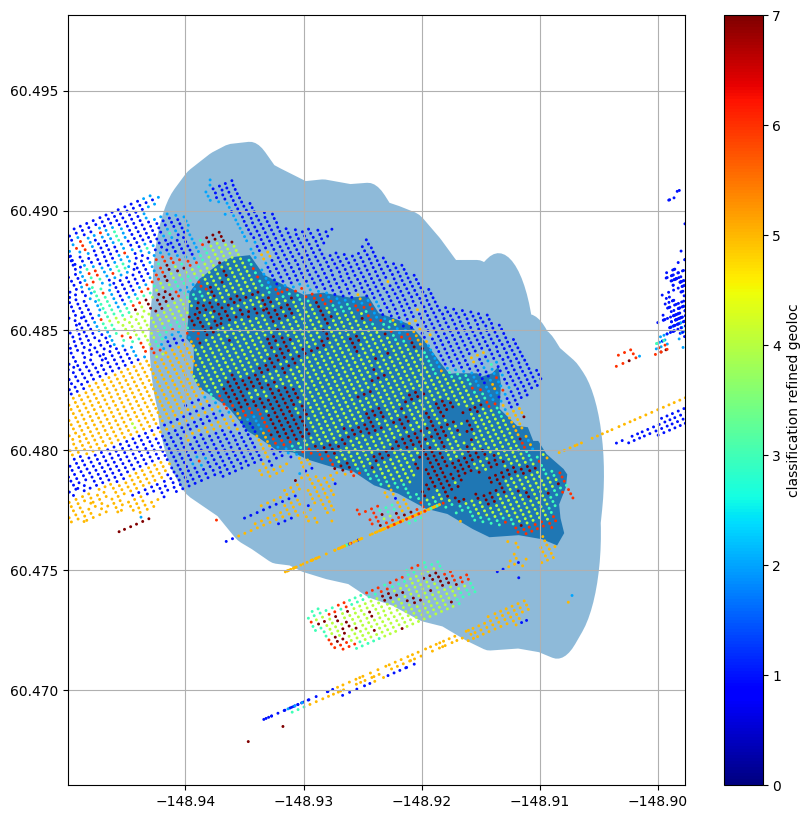

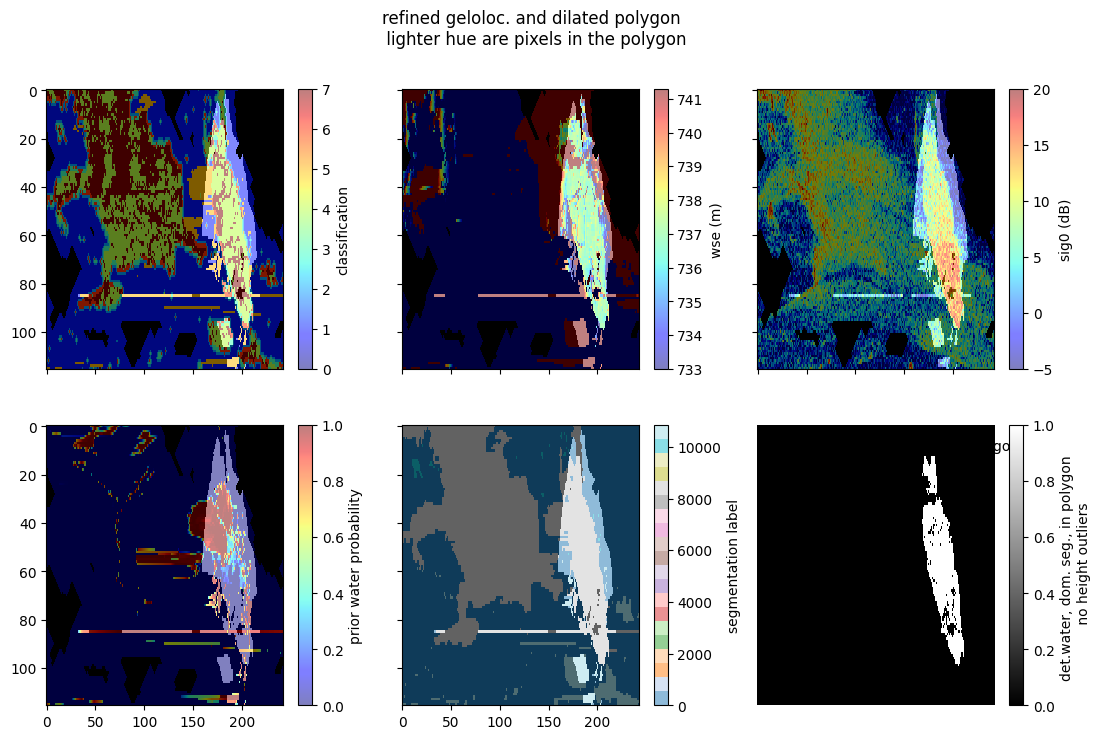

In [9]:
# also get the case without dilating polygon
point_gdf0, point_intx_gdf0, in_mask_2D0 = find_within(
    gdf_d, lat_new, lon_new, msk0)
# also get the masks for pixel assignment after this
masks0 = compute_masks(in_mask_2D0, pixc)

# Now Plot the Bloated-Polygon Case

ax = gdf_d.plot(figsize=(10,10), alpha=0.5)
gdf.plot(ax=ax)
im = ax.scatter(
    lon_new[msk0],
    lat_new[msk0],
    c=pixc['classification'][msk0],
    cmap='jet', clim=(0,7), s=1.2)
ax.set_xlim(float(bbox_df['minx'][0])-buff, float(bbox_df['maxx'][0])+buff)
ax.set_ylim(float(bbox_df['miny'][0])-buff, float(bbox_df['maxy'][0])+buff)
plt.colorbar(im,label='classification refined geoloc')
ax.grid()

# also plot the multipanel

plot_multipanel(in_mask_2D0, pixc,
    final_mask=masks0['water_seg_in_no_outliers'],
    final_label='det.water, dom. seg., in polygon \n no height outliers',
    title='refined geloloc. and dilated polygon')
#plt.savefig('multi_refined_geoloc_dilate.png')

Now observe that we have recovered some regions (e.g., the upper part of the feature) that are

1) detected as water
2) have a similar height/wse
3) are connected in slant plane and
4) are close to the polygon
 
and thus are likley part of the same water feature that was not originally assigned, while also excluding disconnected pixels/features and those whose height/wse and classification are not consistent with the rest of the feature.  In this manner we are able to give the largest collection of pixels that we trust are part of the feature where we also trust the heights.  The consequence is that when we aggregate the heights over this feature we now tend to improve the overall estimate (generally both the bias and uncertainty).

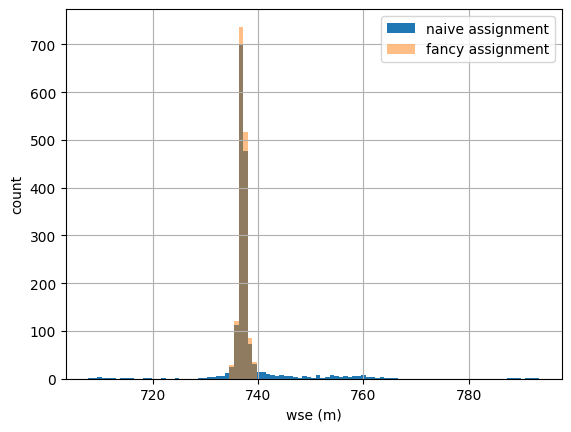

In [10]:
# compare the histograms of the fancy assignement and the naive assignement
wse_naive = pixc['wse'][masks['water_in'] > 0]
wse_fancy = pixc['wse'][masks0['water_seg_in_no_outliers'] > 0]
bins = np.linspace(np.min(wse_naive), np.max(wse_naive), 100)
plt.figure()
plt.hist(wse_naive, bins, label='naive assignment')
plt.hist(wse_fancy, bins, label='fancy assignment', alpha=0.5)
plt.legend()
plt.xlabel('wse (m)')
plt.ylabel('count')
plt.grid()


Note that the naive assignement method has tails with large wse errors, wheras the fancy assignement method mitigates those problematic cases (mostly due to the wse outlier rejection).  Furthermore, the fancy pixel-assignment method actually has more good pixels to average down for the nonanomolous wses (near the central peak).

## Now aggregate wse using the aggregate.py code
Note that there are subtleties also in how best to aggregate the pixel-wise wse over a feature once we have assigned the pixels. A naive approach would be to just take a simple average (or take the median) of the height (or wse).  However, if we have the an estimate of the noise of each pixel (which we do), the optimal approach is to do an inverse-variance-weighted average (though some care needs to be taken in handling anomalies and outliers as well).  This approach is implemented in the RiverObs code in a part of the code in "aggregate.py" and is used by the river, lake, and raster processor to do the height/wse aggregation.  The method also outputs an estimate of the wse uncertainty, which handles non-independence between pixels that is due to the adaptive multilooking in the PIXC algorithm.

Here we will show how to use these already existing functions to get the wse estimate over the region with an estimate of hte remaining uncertainties as well.

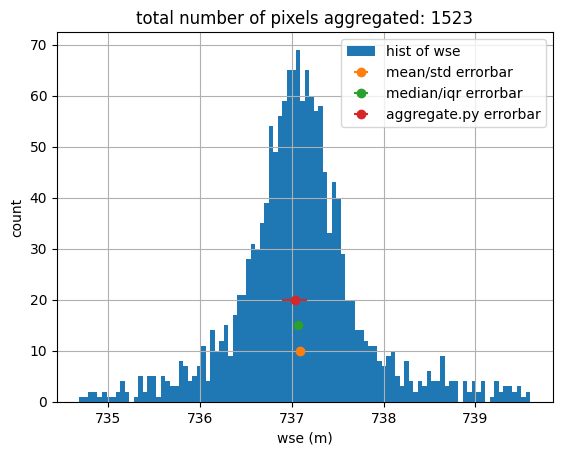

In [11]:

# set up some variables
good = masks0['water_seg_in_no_outliers'] > 0
# Note that this "good" mask is the list of pixels we trust to aggregate
# in general users will want to alo apply quality flags and potentially
# other metrics/variable/qualtities to further subselect pixels with
# trusted height/wse.  Here we neglect the quality flagging, since it
# may generally need to be tuned/adapted for each specific application.
# For example, as a somewhat general rule users would probably want to
# use the ice flag to exclude ice-contanimated data, but this specific
# case is trying to actually observe a glacial lake (which would exclude
# a large percentage of the PIXC data).
method = 'weight'
height_std = pixc['phase_noise_std'] * pixc['dheight_dphase']
#call the estimator
res = SWOTWater.aggregate.height_with_uncerts(
    pixc['wse'],
    good,
    pixc['eff_num_rare_looks'],
    pixc['eff_num_medium_looks'],
    pixc['interferogram'],
    pixc['power_plus_y'],
    pixc['power_minus_y'],
    pixc['looks_to_efflooks'],
    pixc['dheight_dphase'],
    pixc['dlatitude_dphase'],
    pixc['dlongitude_dphase'],
    height_std=height_std,
    method=method)
# unpack the feature wse and uncertainty
f_wse = res[0]
f_wse_u = res[2]
# now also estimate with simple mean and std
f_wse_mean = np.mean(pixc['wse'][good])
f_wse_std = np.std(pixc['wse'][good])
# now estimate with median and iqr
f_wse_median = np.median(pixc['wse'][good])
f_wse_p25 = np.percentile(pixc['wse'][good], 25)
f_wse_p75 = np.percentile(pixc['wse'][good], 75)
f_wse_iqr = f_wse_p75 - f_wse_p25
# get the number of indep samples for the simple std and iqr uncertaity estimates
num =  np.sum(good) # this is an over-estimate since the pixels are correlated
f_wse_u0 = f_wse_std / np.sqrt(num)
f_wse_u1 = f_wse_iqr / np.sqrt(num)

# now plot the histogram of the wse and the central moment estimates with uncertainties
plt.figure()
plt.hist(pixc['wse'][good], 100, label='hist of wse')
plt.errorbar([f_wse_mean,],[10,], xerr=f_wse_u0, fmt='o', label='mean/std errorbar')
plt.errorbar([f_wse_median,],[15,], xerr=f_wse_u1, fmt='o', label='median/iqr errorbar')
plt.errorbar([f_wse,],[20,], xerr=f_wse_u, fmt='o', label='aggregate.py errorbar')
plt.legend()
plt.xlabel('wse (m)')
plt.ylabel('count')
plt.title(f'total number of pixels aggregated: {num}')
plt.grid()

Note that the aggregate.py method produces an estimate of the uncertainty that contains the other methods, while the others are generally too narrow (because they are not accounting for correlation between the pixels that hapens in the medium multilooking).  A true assessment of the fidelity of the uncertainty estimates would generally need more than one case, with come trusted truth source (which is beyond the scope of this tutorial).

*Disclaimer: Reference herein to any specific commercial product, process, or service by trade name, trademark, manufacturer, or otherwise, does not constitute or imply its endorsement by the United States Government or the Jet Propulsion Laboratory, California Institute of Technology.*